# Week 10 — Comparing CT Reconstruction Methods

Three ways to turn a **sinogram** (projections at many angles) back into an image, each rooted in the
theory from `FourierTheory_Parseval_CT.ipynb` and `../Week09/AlgebraicReconstruction_4x4.ipynb`:

1. **Direct Fourier reconstruction** — use the **Fourier Slice Theorem**: 1D-FFT each projection to get
   radial spokes of k-space, grid them onto a Cartesian lattice, then inverse 2D FFT.
2. **Filtered back-projection (FBP)** — the analytic workhorse: **ramp-filter** each projection, then
   smear (back-project) it across the image.
3. **Algebraic reconstruction (ART/SART)** — set up $A\boldsymbol\mu=\mathbf p$ and solve
   **iteratively** (the EMI-scanner / Kaczmarz idea, scaled up).

We compare them on a Shepp–Logan phantom with **full** sampling, **sparse** views, and **noisy** data.

| Method | Speed | Strengths | Weaknesses |
|---|---|---|---|
| Direct Fourier | fast | conceptually exact (slice theorem) | polar→Cartesian **gridding artifacts** |
| FBP | fast | standard, analytic, good with dense views | streaks with few views / noise |
| ART / SART | slow | handles **sparse / noisy / limited-angle** data, priors | iterative cost |

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from numpy.fft import fft, ifft2, fftshift, ifftshift, fftfreq
from scipy.interpolate import griddata
from skimage.data import shepp_logan_phantom
from skimage.transform import radon, iradon, iradon_sart, resize

rng = np.random.default_rng(0)
plt.rcParams["figure.dpi"] = 110

def norm01(a):
    a = a - a.min()
    return a / (a.max() + 1e-12)

def rmse(truth, recon):
    """RMSE after min-max normalizing both (fair across methods with different scales)."""
    return float(np.sqrt(np.mean((norm01(truth) - norm01(recon)) ** 2)))

## 1. Phantom and its sinogram (the Radon transform)

The **sinogram** stacks the projections $p_\theta(s)$ as columns — this is the measured CT data. Here
we simulate it with the forward **Radon transform** over 180 angles.

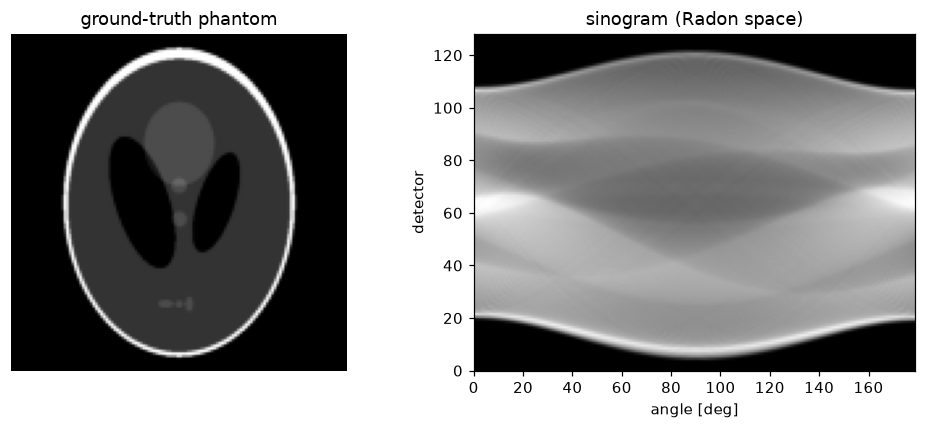

In [2]:
phantom = resize(shepp_logan_phantom(), (128, 128), anti_aliasing=True)
theta = np.arange(0.0, 180.0, 1.0)                 # 180 projection angles
sinogram = radon(phantom, theta=theta, circle=True)
n_det = sinogram.shape[0]

fig, ax = plt.subplots(1, 2, figsize=(9, 4))
ax[0].imshow(phantom, cmap="gray"); ax[0].set_title("ground-truth phantom"); ax[0].axis("off")
ax[1].imshow(sinogram, cmap="gray", aspect="auto",
             extent=(theta.min(), theta.max(), 0, n_det))
ax[1].set_title("sinogram (Radon space)"); ax[1].set_xlabel("angle [deg]"); ax[1].set_ylabel("detector")
plt.tight_layout(); plt.show()

## 2. Filtered back-projection (FBP)

FBP applies the **ramp filter** $|k|$ to every projection (undoing the $1/|k|$ polar oversampling) and
back-projects. With dense, clean views it is fast and accurate — our reference reconstruction.

FBP RMSE = 0.0535


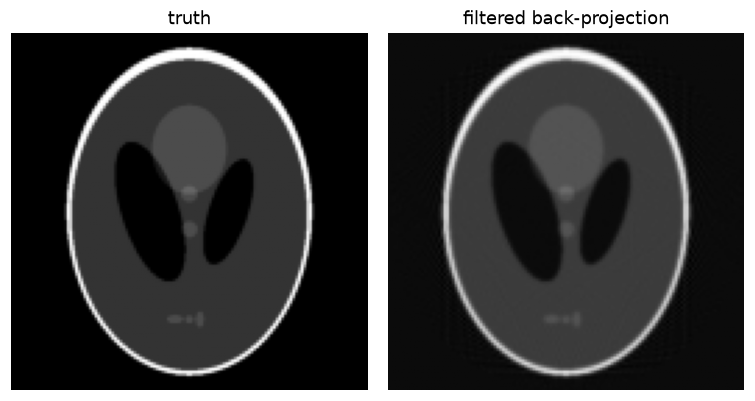

In [3]:
fbp = iradon(sinogram, theta=theta, filter_name="ramp", circle=True)
print(f"FBP RMSE = {rmse(phantom, fbp):.4f}")

fig, ax = plt.subplots(1, 2, figsize=(7, 3.6))
ax[0].imshow(phantom, cmap="gray"); ax[0].set_title("truth"); ax[0].axis("off")
ax[1].imshow(fbp, cmap="gray"); ax[1].set_title("filtered back-projection"); ax[1].axis("off")
plt.tight_layout(); plt.show()

## 3. Direct Fourier reconstruction (gridding)

Straight from the **Fourier Slice Theorem**: 1D-FFT each projection to obtain radial spokes of
k-space, **interpolate** those polar samples onto a Cartesian grid, and inverse 2D FFT. It is elegant
and fast, but the polar→Cartesian interpolation injects **gridding artifacts** (especially at high
frequencies), so it typically looks worse than FBP unless a careful density-compensated gridding
kernel (NUFFT) is used.

Direct Fourier RMSE = 0.2671


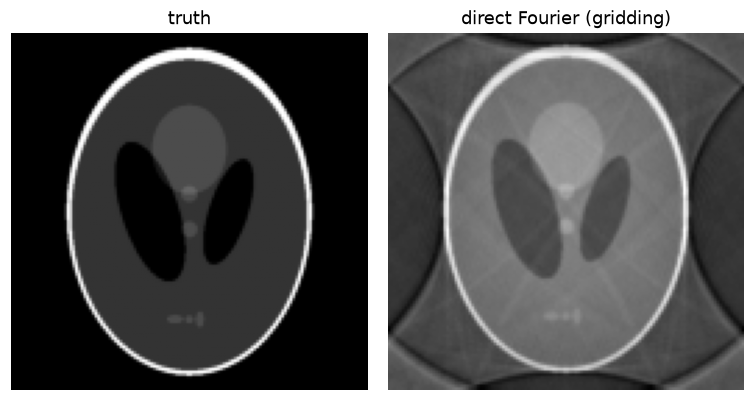

In [5]:
def fourier_reconstruction(sinogram, theta_deg):
    n_det = sinogram.shape[0]
    # 1D FFT of each (centered) projection -> radial spokes of k-space
    proj_fft = fftshift(fft(ifftshift(sinogram, axes=0), axis=0), axes=0)
    freqs = fftshift(fftfreq(n_det))
    ang = np.deg2rad(theta_deg)
    kx = np.outer(freqs, np.cos(ang)).ravel()
    ky = np.outer(freqs, np.sin(ang)).ravel()
    # interpolate polar samples onto a Cartesian k-space grid (real & imag separately)
    gf = fftshift(fftfreq(n_det))
    KX, KY = np.meshgrid(gf, gf)
    gr = griddata((kx, ky), proj_fft.real.ravel(), (KX, KY), method="linear", fill_value=0)
    gi = griddata((kx, ky), proj_fft.imag.ravel(), (KX, KY), method="linear", fill_value=0)
    recon = np.real(fftshift(ifft2(ifftshift(gr + 1j * gi))))
    return np.flipud(recon)                    # match image-row (top-down) orientation

fourier = fourier_reconstruction(sinogram, theta)
print(f"Direct Fourier RMSE = {rmse(phantom, fourier):.4f}")

fig, ax = plt.subplots(1, 2, figsize=(7, 3.6))
ax[0].imshow(phantom, cmap="gray"); ax[0].set_title("truth"); ax[0].axis("off")
ax[1].imshow(fourier, cmap="gray"); ax[1].set_title("direct Fourier (gridding)"); ax[1].axis("off")
plt.tight_layout(); plt.show()

## 4. Algebraic reconstruction (SART)

The algebraic view treats reconstruction as solving $A\boldsymbol\mu=\mathbf p$ (as in the 4×4
notebook) but at image scale. **SART** (Simultaneous Algebraic Reconstruction Technique) is a modern,
well-conditioned relative of Kaczmarz ART; a couple of iterations already give a good image. It is
slower than FBP but far more robust when data are **sparse** or **noisy**.

SART (2 iters) RMSE = 0.0677


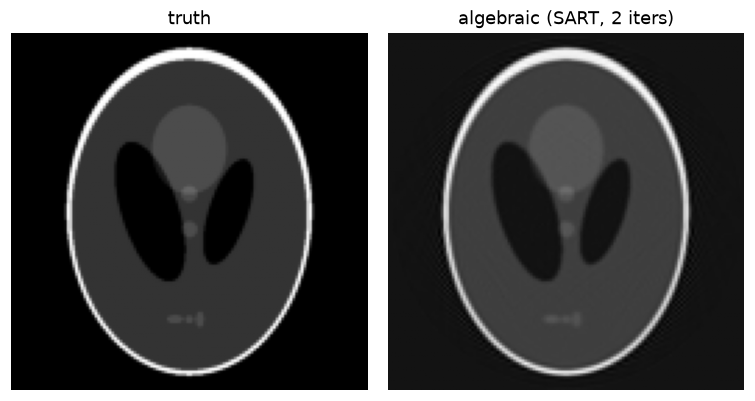

In [6]:
sart = iradon_sart(sinogram, theta=theta)                 # iteration 1
sart = iradon_sart(sinogram, theta=theta, image=sart)     # iteration 2
print(f"SART (2 iters) RMSE = {rmse(phantom, sart):.4f}")

fig, ax = plt.subplots(1, 2, figsize=(7, 3.6))
ax[0].imshow(phantom, cmap="gray"); ax[0].set_title("truth"); ax[0].axis("off")
ax[1].imshow(sart, cmap="gray"); ax[1].set_title("algebraic (SART, 2 iters)"); ax[1].axis("off")
plt.tight_layout(); plt.show()

## 5. Head-to-head (full 180 views)

With dense, clean data all three recover the phantom; **FBP** and **SART** are sharpest, while the
naive **direct Fourier** reconstruction shows the most gridding error.

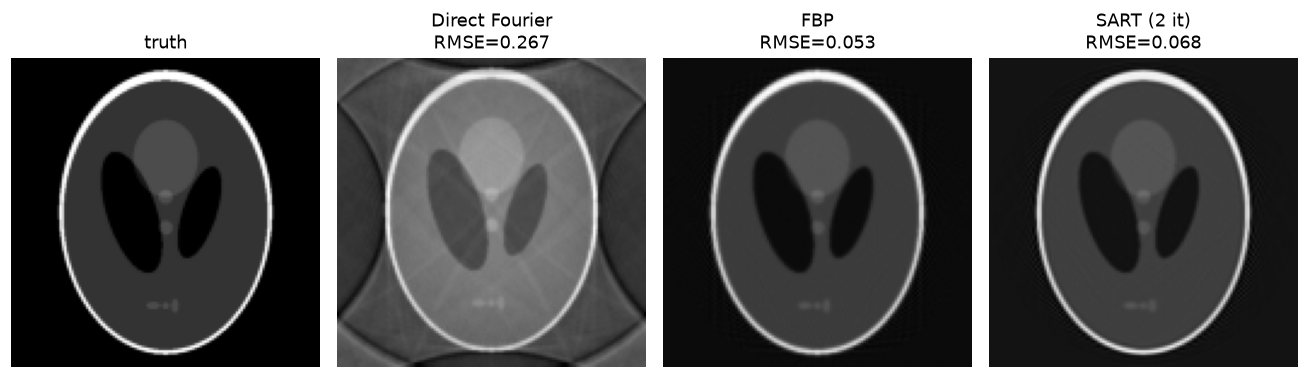

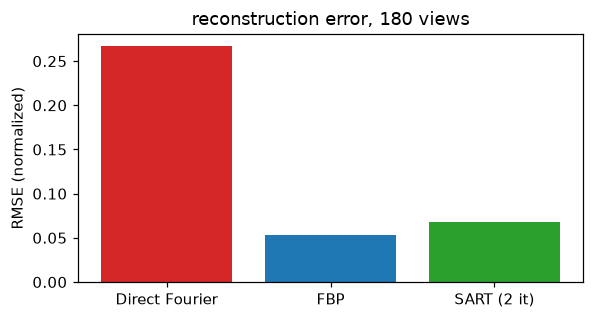

In [7]:
recons = {"Direct Fourier": fourier, "FBP": fbp, "SART (2 it)": sart}

fig, ax = plt.subplots(1, 4, figsize=(12, 3.3))
ax[0].imshow(phantom, cmap="gray"); ax[0].set_title("truth"); ax[0].axis("off")
for a, (name, im) in zip(ax[1:], recons.items()):
    a.imshow(im, cmap="gray"); a.set_title(f"{name}\nRMSE={rmse(phantom, im):.3f}"); a.axis("off")
plt.tight_layout(); plt.show()

plt.figure(figsize=(5.5, 3))
names = list(recons.keys()); errs = [rmse(phantom, im) for im in recons.values()]
plt.bar(names, errs, color=["tab:red", "tab:blue", "tab:green"])
plt.ylabel("RMSE (normalized)"); plt.title("reconstruction error, 180 views")
plt.tight_layout(); plt.show()

## 6. Sparse views: where algebraic methods shine

Real scans trade views for **dose/time**. With only a handful of angles, FBP develops prominent
**streak artifacts** (k-space is left mostly empty between spokes), whereas the iterative **SART**
degrades more gracefully because it enforces consistency with *all* rays simultaneously.

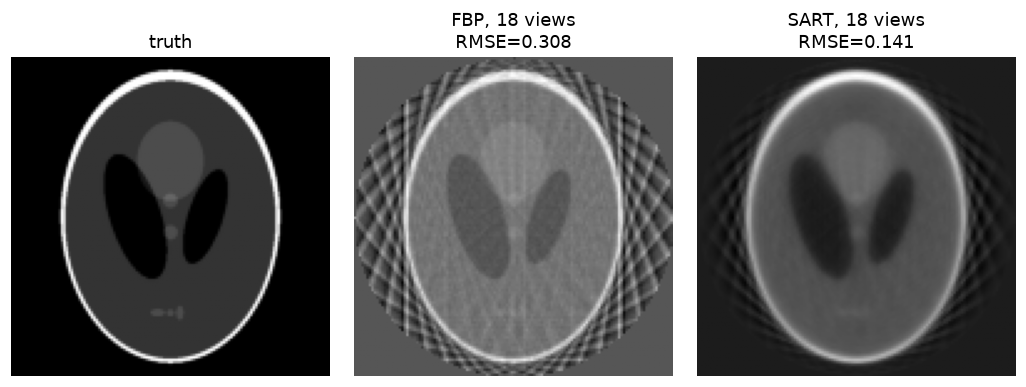

In [8]:
theta_sparse = np.linspace(0.0, 180.0, 18, endpoint=False)     # only 18 views
sino_sparse = radon(phantom, theta=theta_sparse, circle=True)

fbp_s = iradon(sino_sparse, theta=theta_sparse, filter_name="ramp", circle=True)
sart_s = iradon_sart(sino_sparse, theta=theta_sparse)
sart_s = iradon_sart(sino_sparse, theta=theta_sparse, image=sart_s)

fig, ax = plt.subplots(1, 3, figsize=(9.5, 3.4))
ax[0].imshow(phantom, cmap="gray"); ax[0].set_title("truth"); ax[0].axis("off")
ax[1].imshow(fbp_s, cmap="gray"); ax[1].set_title(f"FBP, 18 views\nRMSE={rmse(phantom, fbp_s):.3f}"); ax[1].axis("off")
ax[2].imshow(sart_s, cmap="gray"); ax[2].set_title(f"SART, 18 views\nRMSE={rmse(phantom, sart_s):.3f}"); ax[2].axis("off")
plt.tight_layout(); plt.show()

## 7. Noisy projections

Detectors count photons, so projections carry noise. Adding noise to the (full-view) sinogram, FBP's
ramp filter **amplifies high-frequency noise**; SART's implicit regularization keeps it a little
smoother.

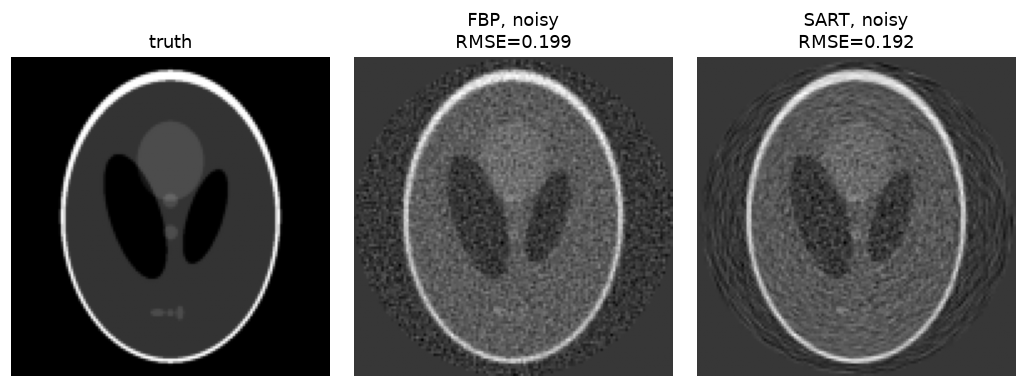

In [9]:
noise_sigma = 0.05 * sinogram.max()
sino_noisy = sinogram + rng.normal(0, noise_sigma, size=sinogram.shape)

fbp_n = iradon(sino_noisy, theta=theta, filter_name="ramp", circle=True)
sart_n = iradon_sart(sino_noisy, theta=theta)
sart_n = iradon_sart(sino_noisy, theta=theta, image=sart_n)

fig, ax = plt.subplots(1, 3, figsize=(9.5, 3.4))
ax[0].imshow(phantom, cmap="gray"); ax[0].set_title("truth"); ax[0].axis("off")
ax[1].imshow(fbp_n, cmap="gray"); ax[1].set_title(f"FBP, noisy\nRMSE={rmse(phantom, fbp_n):.3f}"); ax[1].axis("off")
ax[2].imshow(sart_n, cmap="gray"); ax[2].set_title(f"SART, noisy\nRMSE={rmse(phantom, sart_n):.3f}"); ax[2].axis("off")
plt.tight_layout(); plt.show()

## Takeaways

- All three methods invert the **same** data (the sinogram) but take different routes: **Fourier**
  (k-space gridding), **FBP** (ramp-filter + back-project), **ART/SART** (iteratively solve
  $A\boldsymbol\mu=\mathbf p$).
- With **dense, clean** views, **FBP** is the fast, accurate standard; naive **direct Fourier** suffers
  from polar→Cartesian **gridding artifacts** (fixable with NUFFT/density compensation).
- With **sparse views** or **noise**, iterative **SART** degrades more gracefully — the reason modern
  scanners use **iterative reconstruction** to cut dose.
- The connective tissue is the **Fourier Slice Theorem**: projections are radial lines of k-space;
  every method is a different way of filling and inverting that space.
- Trade-off in one line: **Fourier/FBP = speed**, **ART/SART = robustness** (sparse, noisy,
  limited-angle, or with priors).